In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import pandas as pd
import optuna

from scipy.interpolate import interp1d
from scipy.integrate import solve_ivp
from scipy.signal import savgol_filter

from PINN_SEIR import PINN_with_params, gradients, loss_fn_params, get_region_dates

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

c:\Users\Yascher\Desktop\Science\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


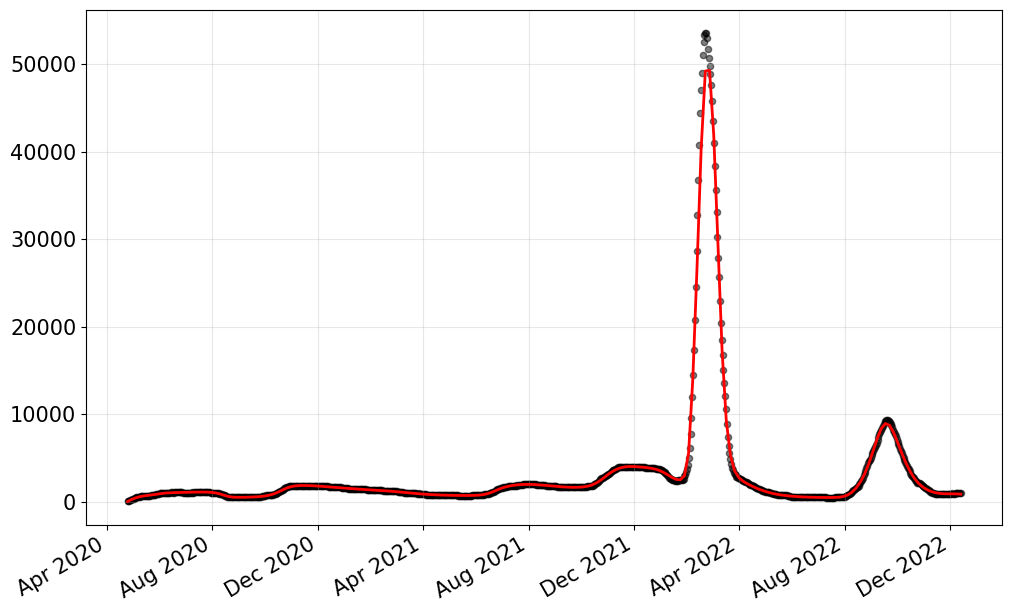

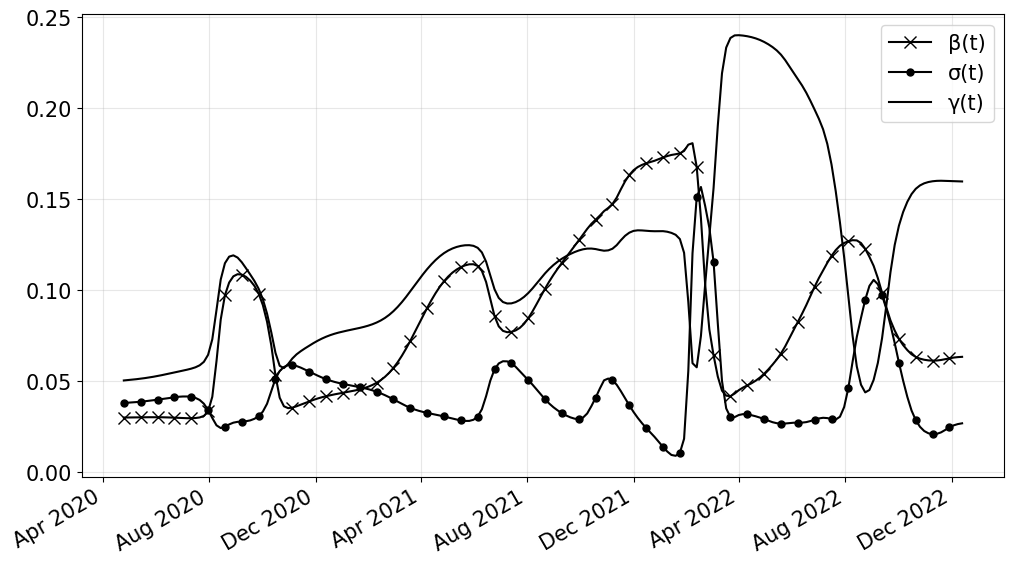

In [5]:
# 1. Загружаем данные региона
N_POP = 200
POP_TOTAL = 2780292
df_nsk = pd.read_csv('I_data.csv')
I_frac_new = df_nsk['new_diagnoses'][44:1007].to_numpy()  # или другая численность региона
cases_smooth = pd.Series(I_frac_new).rolling(window=7, min_periods=1, center=True).mean().to_numpy()

DISEASE_DURATION = 10  # дней
dates_nsk, dates_pred_nsk = get_region_dates(df_nsk, date_col='Date', start_idx=44, end_idx=1007, n_points=200)
# Вычисляем скользящую сумму назад по времени:
I_window_sum = pd.Series(I_frac_new).rolling(
    window=DISEASE_DURATION, 
    min_periods=1
).sum().to_numpy()
I_nsk = I_window_sum[:, None]
I_data = (I_window_sum)[:, None] / POP_TOTAL * N_POP
T = len(I_data)
t_test = torch.linspace(-1, 1, 200, device=device).reshape(-1,1)
# 2. Создаём новую модель
model_new = PINN_with_params([1, 128, 128, 128, 128, 128, 3], [1, 128, 128, 128, 3], N_POP, T).to(device)

# 3. Загружаем веса из исходного региона
checkpoint = torch.load('pinn_seir_nsk.pth')
model_new.load_state_dict(checkpoint['model_state_dict'])
loss_w = checkpoint['loss_weights']
loss_weights = (loss_w['w_pde_S'], loss_w['w_pde_E'], loss_w['w_pde_I'], loss_w['w_pde_R'], loss_w['w_ic_E'], loss_w['w_ic_I'], loss_w['w_ic_R'], loss_w['w_data_I'], loss_w['w_mono_S'], loss_w['w_mono_R'])

E_pred, I_pred, R_pred, beta_pred, sigma_pred, gamma_pred, E0_pred = model_new(t_test)
S_pred = N_POP - E_pred - I_pred - R_pred

S_pred_nsk = S_pred.cpu().detach().numpy()
E_pred = E_pred.cpu().detach().numpy()    
I_pred = I_pred.cpu().detach().numpy()
R_pred = R_pred.cpu().detach().numpy()
beta_pred_nsk = beta_pred.cpu().detach().numpy()
sigma_pred_nsk = sigma_pred.cpu().detach().numpy()
gamma_pred_nsk = gamma_pred.cpu().detach().numpy()

fig, ax = plt.subplots(figsize=(10, 6))
# ax.plot(dates_pred_nsk, S_pred_nsk*POP_TOTAL/N_POP, label="S_pred", linewidth=2, color='blue')
# ax.plot(dates_pred_nsk, E_pred*POP_TOTAL/N_POP, label="E_pred", linewidth=2, color='purple')
ax.plot(dates_pred_nsk, I_pred*POP_TOTAL/N_POP, label="I_pred", linewidth=2, color='red')
# ax.plot(dates_pred_nsk, R_pred*POP_TOTAL/N_POP, label="R_pred", linewidth=2, color='black')
ax.scatter(dates_nsk, (I_window_sum)[:, None].flatten(), s=20, label="I_true", alpha=0.5, color='black')
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.tight_layout()
plt.tick_params(labelsize=15)
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(dates_pred_nsk, beta_pred_nsk/T*2, label="β(t)", color='black', marker='x', markersize=8, markevery=4)
plt.grid(True, alpha=0.3)
plt.plot(dates_pred_nsk, sigma_pred_nsk/T*2, label="σ(t)", color='black', marker='.', markersize=10, markevery=4)
plt.plot(dates_pred_nsk, gamma_pred_nsk/T*2, label="γ(t)", color='black')
plt.tight_layout()
plt.tick_params(labelsize=15)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.legend(fontsize=15)
plt.show()

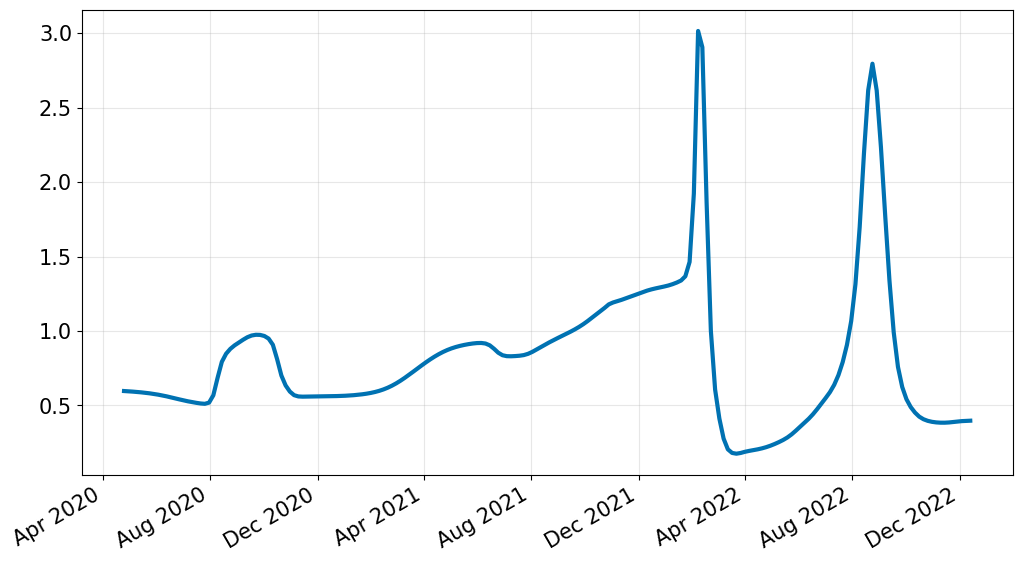

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(dates_pred_nsk, beta_pred_nsk/gamma_pred_nsk, label="β(t)", color='#0072B2', linewidth=3)
ax.grid(True, alpha=0.3)
plt.tight_layout()
ax.tick_params(labelsize=15)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.show()

In [7]:
def sir_ode(t, y):
    S, E, I, R = y
    beta_val = beta_interp(t) / (N_POP)
    sigma_val = sigma_interp(t)
    gamma_val = gamma_interp(t)

    dS = -beta_val * S * I
    dE = beta_val * S * I - sigma_val * E
    dI = sigma_val * E - gamma_val * I
    dR = gamma_val * I
    return [dS, dE, dI, dR]

# коллокационные точки
N = 3000
t_colloc = 2 * torch.rand(N,1, device=device) - 1

## Санкт-Петербург

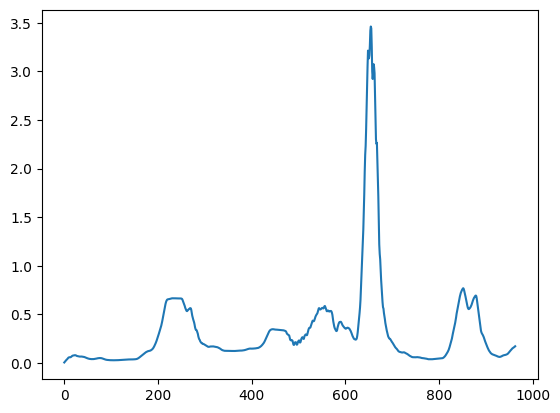

C:\Users\Yascher\AppData\Local\Temp\ipykernel_31980\3698122395.py:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  I0_frac_new = float(I_data[0])
c:\Users\Yascher\Desktop\Science\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:1699: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  current = float(metrics)


Epoch 0, loss=552.500061, loss_data=1.856905
Epoch 500, loss=20.985565, loss_data=0.264680
Epoch 1000, loss=9.603601, loss_data=0.103491
Epoch 1500, loss=6.694139, loss_data=0.070483
Epoch 2000, loss=4.399993, loss_data=0.041499
Epoch 2500, loss=3.358764, loss_data=0.027363
Epoch 3000, loss=2.925749, loss_data=0.021752
Epoch 3500, loss=2.682456, loss_data=0.018587
Epoch 4000, loss=2.528499, loss_data=0.016506
Epoch 4500, loss=2.414681, loss_data=0.014935
Epoch 5000, loss=2.340802, loss_data=0.013647


In [9]:
N_POP = 100
POP_TOTAL = 5652922
df_spb = pd.read_csv('spb_data.csv')
I_frac_new = df_spb['new_diagnoses'][44:1007].to_numpy()  # или другая численность региона
cases_smooth = pd.Series(I_frac_new).rolling(window=7, min_periods=1, center=True).mean().to_numpy()
DISEASE_DURATION = 10  # дней
dates_spb, dates_pred_spb = get_region_dates(df_spb, date_col='Date', start_idx=44, end_idx=1007, n_points=200)
I_window_sum = pd.Series(I_frac_new).rolling(
    window=DISEASE_DURATION, 
    min_periods=1
).sum().to_numpy()
I_spb = I_window_sum[:, None]
I_data = (I_window_sum)[:, None] / POP_TOTAL * N_POP
T = len(I_data)
plt.plot(I_data)
plt.show()
model_new = PINN_with_params([1, 128, 128, 128, 128, 128, 3], [1, 128, 128, 128, 3], N_POP, T).to(device)

checkpoint = torch.load('pinn_seir_nsk.pth')
model_new.load_state_dict(checkpoint['model_state_dict'])
loss_w = checkpoint['loss_weights']
loss_weights = (loss_w['w_pde_S'], loss_w['w_pde_E'], loss_w['w_pde_I'], loss_w['w_pde_R'], loss_w['w_ic_E'], loss_w['w_ic_I'], loss_w['w_ic_R'], loss_w['w_data_I'], loss_w['w_mono_S'], loss_w['w_mono_R'])

I0_frac_new = float(I_data[0])
E0_frac_new = I0_frac_new * 3.0
R0_frac_new = 0.0
S0_frac_new = N_POP - I0_frac_new - E0_frac_new - R0_frac_new

I0_new = torch.tensor([[I0_frac_new * N_POP]], dtype=torch.float32, device=device)
# E0_new = torch.tensor([[E0_frac_new * N_POP]], dtype=torch.float32, device=device)
R0_new = torch.tensor([[R0_frac_new * N_POP]], dtype=torch.float32, device=device)
S0_new = torch.tensor([[S0_frac_new * N_POP]], dtype=torch.float32, device=device)

days = np.linspace(-1, 1, len(I_data))[:, None]
t_data_new = torch.tensor(days, dtype=torch.float32, device=device)  # дни те же
I_data_tensor_new = torch.tensor(I_data, dtype=torch.float32, device=device)


optimizer_finetune = torch.optim.Adam(
    model_new.parameters(), 
    lr=loss_w['lr']/15,
    weight_decay=loss_w['weight_decay']
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_finetune,
    mode='min',
    factor=0.5,
    patience=300,
    min_lr=1e-6
)

for epoch in range(5001):
    optimizer_finetune.zero_grad()
    
    loss, loss_data = loss_fn_params(
        model_new,
        t_colloc,
        t_data_new,
        I_data_tensor_new,
        S0_new, I0_new, R0_new,
        weights=loss_weights
    )
    
    loss.backward()
    optimizer_finetune.step()
    scheduler.step(loss)
    
    if epoch % 500 == 0:
        print(f"Epoch {epoch}, loss={loss.item():.6f}, loss_data={loss_data:.6f}")

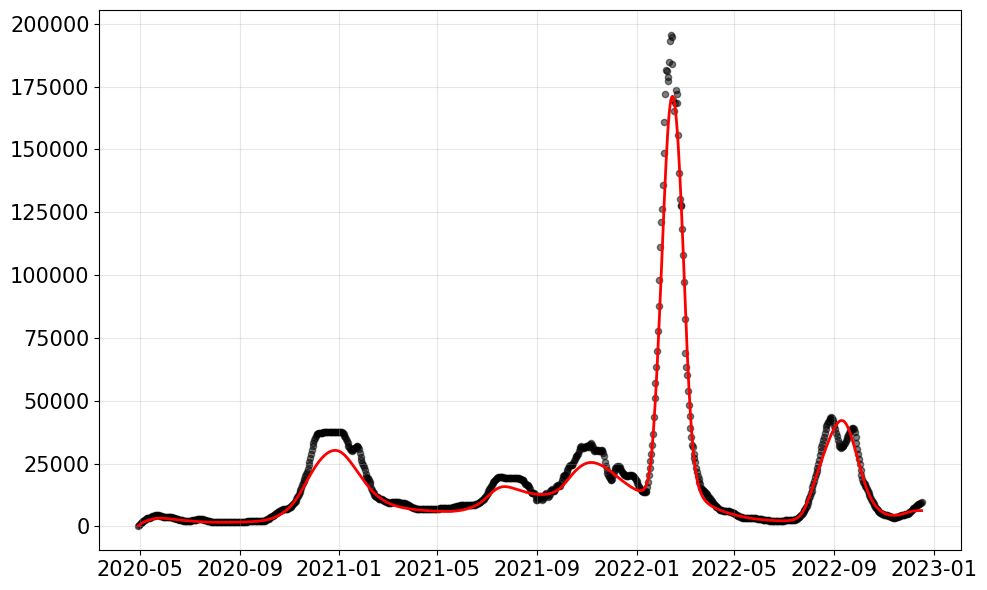

In [12]:
t_test = torch.linspace(-1, 1, 200, device=device).reshape(-1,1)
T = len(I_data)
E_pred, I_pred, R_pred, beta_pred, sigma_pred, gamma_pred, E0_pred = model_new(t_test)
S_pred = N_POP - E_pred - I_pred - R_pred

S_pred_spb = S_pred.cpu().detach().numpy()
E_pred = E_pred.cpu().detach().numpy()    
I_pred = I_pred.cpu().detach().numpy()
R_pred = R_pred.cpu().detach().numpy()
beta_pred_spb = beta_pred.cpu().detach().numpy()
sigma_pred_spb = sigma_pred.cpu().detach().numpy()
gamma_pred_spb = gamma_pred.cpu().detach().numpy()

beta_interp = interp1d(t_test.cpu().numpy().flatten(), beta_pred_spb.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')
sigma_interp = interp1d(t_test.cpu().numpy().flatten(), sigma_pred_spb.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')
gamma_interp = interp1d(t_test.cpu().numpy().flatten(), gamma_pred_spb.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')

E0_found = 5*torch.sigmoid(model_new.E0_raw).item()

I0 = I_data[0].item()
E0 = E0_found
R0 = 0.0
S0 = N_POP - I0 - E0 - R0
t_eval = np.linspace(-1, 1, T)
sol = solve_ivp(sir_ode, (-1, 1), [S0, E0, I0, R0], t_eval=t_eval, rtol=1e-8)

S_ode = sol.y[0]
E_ode = sol.y[1]
I_ode_spb = sol.y[2]
R_ode = sol.y[3]

plt.figure(figsize=(10, 6))
# plt.plot(t_eval_norm, S_ode, 'r-', label='I (reverse)', linewidth=2)
# plt.plot(t_eval, E_ode, 'g-', label='E (reverse)', linewidth=2)
plt.plot(dates_spb, I_ode_spb*POP_TOTAL/N_POP, label="I_pred", linewidth=2, color='red')
# plt.plot(t_test, R_pred, label="R_pred", linewidth=2, color='black')
plt.scatter(dates_spb, I_spb.flatten(), s=20, label="I_true", alpha=0.5, color='black')
plt.grid(True, alpha=0.3)
plt.tick_params(labelsize=15)

plt.tight_layout()
plt.show()

## Москва

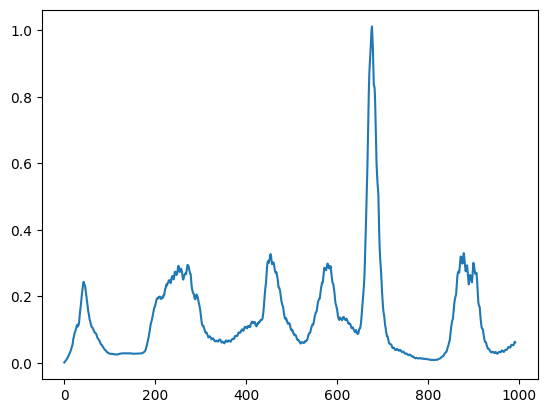

C:\Users\Yascher\AppData\Local\Temp\ipykernel_31980\2372099140.py:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  I0_frac_new = float(I_data[0])


Epoch 0, loss=243.351807, loss_data=1.753803
Epoch 500, loss=8.863245, loss_data=0.100330
Epoch 1000, loss=4.914517, loss_data=0.050937
Epoch 1500, loss=3.047549, loss_data=0.028448
Epoch 2000, loss=2.221857, loss_data=0.019468
Epoch 2500, loss=1.842093, loss_data=0.015678
Epoch 3000, loss=1.626089, loss_data=0.013759
Epoch 3500, loss=1.540100, loss_data=0.012569
Epoch 4000, loss=1.379732, loss_data=0.011635
Epoch 4500, loss=1.309362, loss_data=0.010952
Epoch 5000, loss=1.240875, loss_data=0.010400
Epoch 5500, loss=1.182943, loss_data=0.009913
Epoch 6000, loss=1.126824, loss_data=0.009417
Epoch 6500, loss=1.084647, loss_data=0.008983
Epoch 7000, loss=1.043276, loss_data=0.008531
Epoch 7500, loss=1.007595, loss_data=0.008157
Epoch 8000, loss=0.977171, loss_data=0.007879
Epoch 8500, loss=0.951191, loss_data=0.007632
Epoch 9000, loss=0.931863, loss_data=0.007402
Epoch 9500, loss=0.907067, loss_data=0.007164
Epoch 10000, loss=1.114786, loss_data=0.006934


In [13]:
N_POP = 55
POP_TOTAL = 13274285
df_msk = pd.read_csv('mos_data.csv')
I_frac_new = df_msk['new_diagnoses'][14:1007].to_numpy()  # или другая численность региона
cases_smooth = pd.Series(I_frac_new).rolling(window=7, min_periods=1, center=True).mean().to_numpy()
DISEASE_DURATION = 10  # дней
dates_msk, dates_pred_msk = get_region_dates(df_msk, date_col='Date', start_idx=14, end_idx=1007, n_points=200)
I_window_sum = pd.Series(I_frac_new).rolling(
    window=DISEASE_DURATION, 
    min_periods=1
).sum().to_numpy()
I_msk = I_window_sum[:, None]
I_data = (I_window_sum)[:, None] / POP_TOTAL * N_POP
T = len(I_data)
plt.plot(I_data)
plt.show()
model_new = PINN_with_params([1, 128, 128, 128, 128, 128, 3], [1, 128, 128, 128, 3], N_POP, T).to(device)

checkpoint = torch.load('pinn_seir_nsk.pth')
model_new.load_state_dict(checkpoint['model_state_dict'])
loss_w = checkpoint['loss_weights']
loss_weights = (loss_w['w_pde_S'], loss_w['w_pde_E'], loss_w['w_pde_I'], loss_w['w_pde_R'], loss_w['w_ic_E'], loss_w['w_ic_I'], loss_w['w_ic_R'], loss_w['w_data_I'], loss_w['w_mono_S'], loss_w['w_mono_R'])

I0_frac_new = float(I_data[0])
E0_frac_new = I0_frac_new * 3.0
R0_frac_new = 0.0
S0_frac_new = N_POP - I0_frac_new - E0_frac_new - R0_frac_new

I0_new = torch.tensor([[I0_frac_new * N_POP]], dtype=torch.float32, device=device)
# E0_new = torch.tensor([[E0_frac_new * N_POP]], dtype=torch.float32, device=device)
R0_new = torch.tensor([[R0_frac_new * N_POP]], dtype=torch.float32, device=device)
S0_new = torch.tensor([[S0_frac_new * N_POP]], dtype=torch.float32, device=device)


days = np.linspace(-1, 1, len(I_data))[:, None]
t_data_new = torch.tensor(days, dtype=torch.float32, device=device)  # дни те же
I_data_tensor_new = torch.tensor(I_data, dtype=torch.float32, device=device)


optimizer_finetune = torch.optim.Adam(
    model_new.parameters(), 
    lr=loss_w['lr']/15,          # В 10 раз меньше, чем при обучении с нуля
    weight_decay=loss_w['weight_decay']
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_finetune,
    mode='min',
    factor=0.5,
    patience=300,
    min_lr=1e-6
)


for epoch in range(10001):
    optimizer_finetune.zero_grad()
    
    loss, loss_data = loss_fn_params(
        model_new,
        t_colloc,
        t_data_new,
        I_data_tensor_new,
        S0_new, I0_new, R0_new,
        weights=loss_weights
    )
    
    loss.backward()
    optimizer_finetune.step()
    scheduler.step(loss)
    
    if epoch % 500 == 0:
        print(f"Epoch {epoch}, loss={loss.item():.6f}, loss_data={loss_data:.6f}")

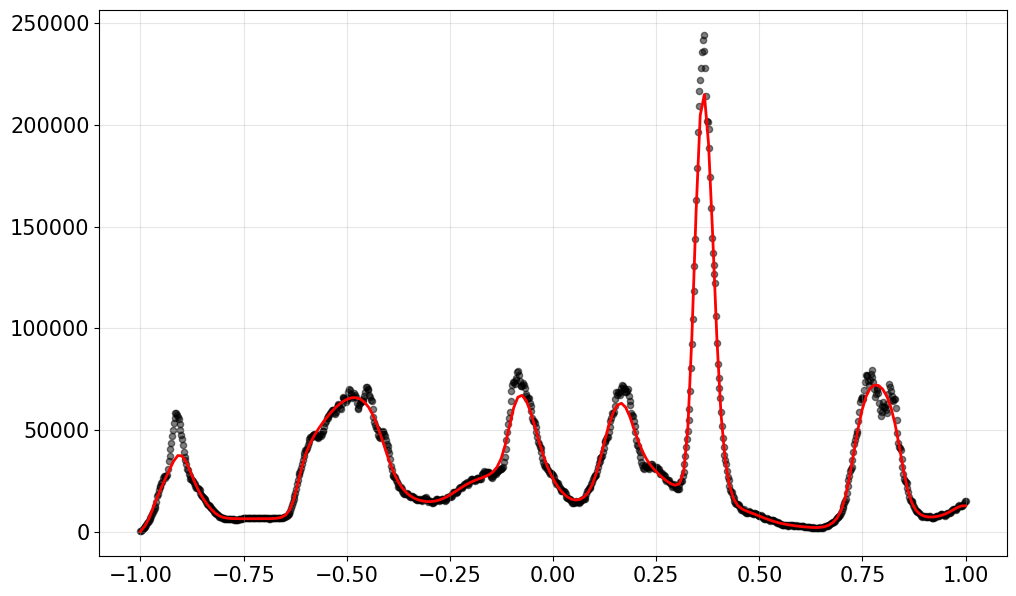

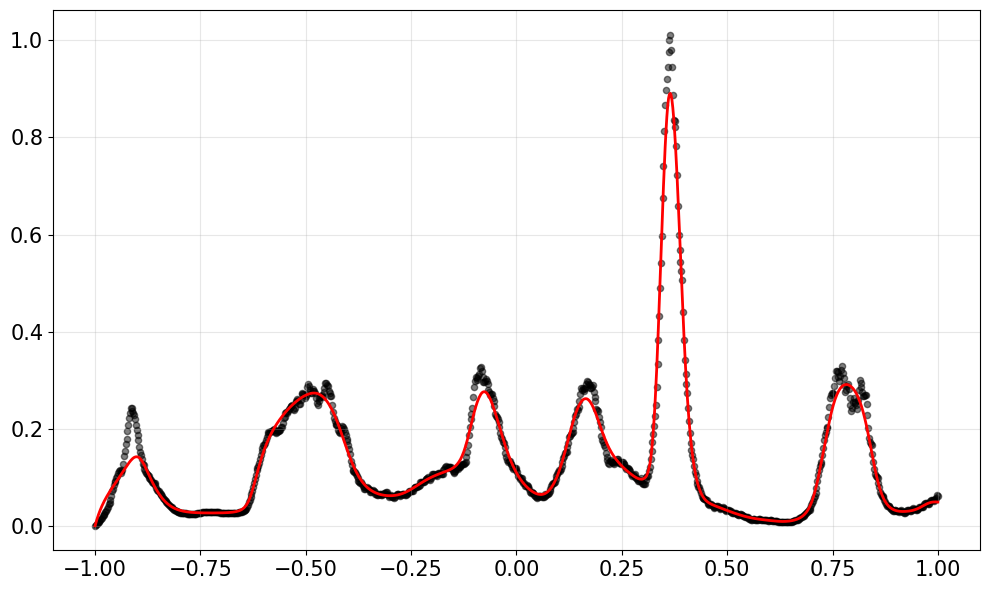

In [16]:
t_test = torch.linspace(-1, 1, 200, device=device).reshape(-1,1)
E_pred, I_pred, R_pred, beta_pred, sigma_pred, gamma_pred, E0_pred = model_new(t_test)
S_pred = N_POP - E_pred - I_pred - R_pred

S_pred_msk = S_pred.cpu().detach().numpy()
E_pred = E_pred.cpu().detach().numpy()    
I_pred = I_pred.cpu().detach().numpy()
R_pred = R_pred.cpu().detach().numpy()
beta_pred_msk = beta_pred.cpu().detach().numpy()
sigma_pred_msk = sigma_pred.cpu().detach().numpy()
gamma_pred_msk = gamma_pred.cpu().detach().numpy()

plt.figure(figsize=(10, 6))
# plt.plot(t_test, S_pred, label="S_pred", linewidth=2, color='blue')
# plt.plot(t_test, E_pred, label="E_pred", linewidth=2, color='purple')
plt.plot(t_test.cpu().numpy().flatten(), I_pred*POP_TOTAL/N_POP, label="I_pred", linewidth=2, color='red')
# plt.plot(t_test, R_pred, label="R_pred", linewidth=2, color='black')
plt.scatter(days, I_msk.flatten(), s=20, label="I_true", alpha=0.5, color='black')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.tick_params(labelsize=15)
plt.show()


beta_interp = interp1d(t_test.cpu().numpy().flatten(), beta_pred_msk.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')
sigma_interp = interp1d(t_test.cpu().numpy().flatten(), sigma_pred_msk.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')
gamma_interp = interp1d(t_test.cpu().numpy().flatten(), gamma_pred_msk.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')

E0_found = 5*torch.sigmoid(model_new.E0_raw).item()

I0 = I_data[0].item()
E0 = E0_found
R0 = 0.0
S0 = N_POP - I0 - E0 - R0
t_eval = np.linspace(-1, 1, T)
sol = solve_ivp(sir_ode, (-1, 1), [S0, E0, I0, R0], t_eval=t_eval, rtol=1e-8)

S_ode = sol.y[0]
E_ode = sol.y[1]
I_ode_msk = sol.y[2]
R_ode = sol.y[3]

plt.figure(figsize=(10, 6))
# plt.plot(t_eval_norm, S_ode, 'r-', label='I (reverse)', linewidth=2)
# plt.plot(t_eval, E_ode, 'g-', label='E (reverse)', linewidth=2)
plt.plot(t_eval, I_ode_msk, label="I_pred", linewidth=2, color='red')
# plt.plot(t_test, R_pred, label="R_pred", linewidth=2, color='black')
plt.scatter(days, I_data.flatten(), s=20, label="I_true", alpha=0.5, color='black')
plt.grid(True, alpha=0.3)
plt.tick_params(labelsize=15)

plt.tight_layout()
plt.show()

## Омская область

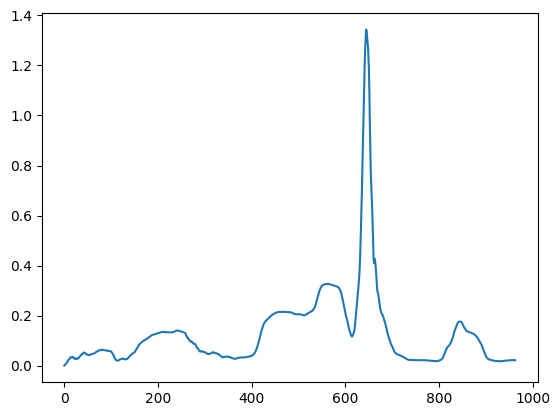

C:\Users\Yascher\AppData\Local\Temp\ipykernel_31980\3080966786.py:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  I0_frac_new = float(I_data[0])


Epoch 0, loss=488.547546, loss_data=0.752346
Epoch 500, loss=12.329933, loss_data=0.179591
Epoch 1000, loss=6.364456, loss_data=0.093990
Epoch 1500, loss=4.217648, loss_data=0.061661
Epoch 2000, loss=2.848252, loss_data=0.040103
Epoch 2500, loss=2.008615, loss_data=0.026630
Epoch 3000, loss=1.476748, loss_data=0.018453
Epoch 3500, loss=1.128417, loss_data=0.013238
Epoch 4000, loss=0.914558, loss_data=0.010073
Epoch 4500, loss=0.784593, loss_data=0.008208
Epoch 5000, loss=0.698010, loss_data=0.007020


In [17]:
N_POP = 100
POP_TOTAL = 1805806
df_omsk = pd.read_csv('omsk-region-data.csv')
I_frac_new = df_omsk['new_diagnoses'][44:1007].to_numpy()
cases_smooth = pd.Series(I_frac_new).rolling(window=7, min_periods=1, center=True).mean().to_numpy()
DISEASE_DURATION = 10  # дней
dates_omsk, dates_pred_omsk = get_region_dates(df_omsk, date_col='date', start_idx=44, end_idx=1007, n_points=200)
I_window_sum = pd.Series(I_frac_new).rolling(
    window=DISEASE_DURATION, 
    min_periods=1
).sum().to_numpy()
I_omsk = I_window_sum[:, None]
I_data = (I_window_sum)[:, None] / POP_TOTAL * N_POP
T = len(I_data)
plt.plot(I_data)
plt.show()
model_new = PINN_with_params([1, 128, 128, 128, 128, 128, 3], [1, 128, 128, 128, 3], N_POP, T).to(device)

checkpoint = torch.load('pinn_seir_nsk.pth')
model_new.load_state_dict(checkpoint['model_state_dict'])
loss_w = checkpoint['loss_weights']
loss_weights = (loss_w['w_pde_S'], loss_w['w_pde_E'], loss_w['w_pde_I'], loss_w['w_pde_R'], loss_w['w_ic_E'], loss_w['w_ic_I'], loss_w['w_ic_R'], loss_w['w_data_I'], loss_w['w_mono_S'], loss_w['w_mono_R'])

I0_frac_new = float(I_data[0])
E0_frac_new = I0_frac_new * 3.0
R0_frac_new = 0.0
S0_frac_new = N_POP - I0_frac_new - E0_frac_new - R0_frac_new

I0_new = torch.tensor([[I0_frac_new * N_POP]], dtype=torch.float32, device=device)
# E0_new = torch.tensor([[E0_frac_new * N_POP]], dtype=torch.float32, device=device)
R0_new = torch.tensor([[R0_frac_new * N_POP]], dtype=torch.float32, device=device)
S0_new = torch.tensor([[S0_frac_new * N_POP]], dtype=torch.float32, device=device)

days = np.linspace(-1, 1, len(I_data))[:, None]
t_data_new = torch.tensor(days, dtype=torch.float32, device=device)
I_data_tensor_new = torch.tensor(I_data, dtype=torch.float32, device=device)

optimizer_finetune = torch.optim.Adam(
    model_new.parameters(), 
    lr=loss_w['lr']/15,
    weight_decay=loss_w['weight_decay']
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_finetune,
    mode='min',
    factor=0.5,
    patience=300,
    min_lr=1e-6
)

for epoch in range(5001):
    optimizer_finetune.zero_grad()
    
    loss, loss_data = loss_fn_params(
        model_new,
        t_colloc,
        t_data_new,
        I_data_tensor_new,
        S0_new, I0_new, R0_new,
        weights=loss_weights
    )
    
    loss.backward()
    optimizer_finetune.step()
    scheduler.step(loss)
    
    if epoch % 500 == 0:
        print(f"Epoch {epoch}, loss={loss.item():.6f}, loss_data={loss_data:.6f}")

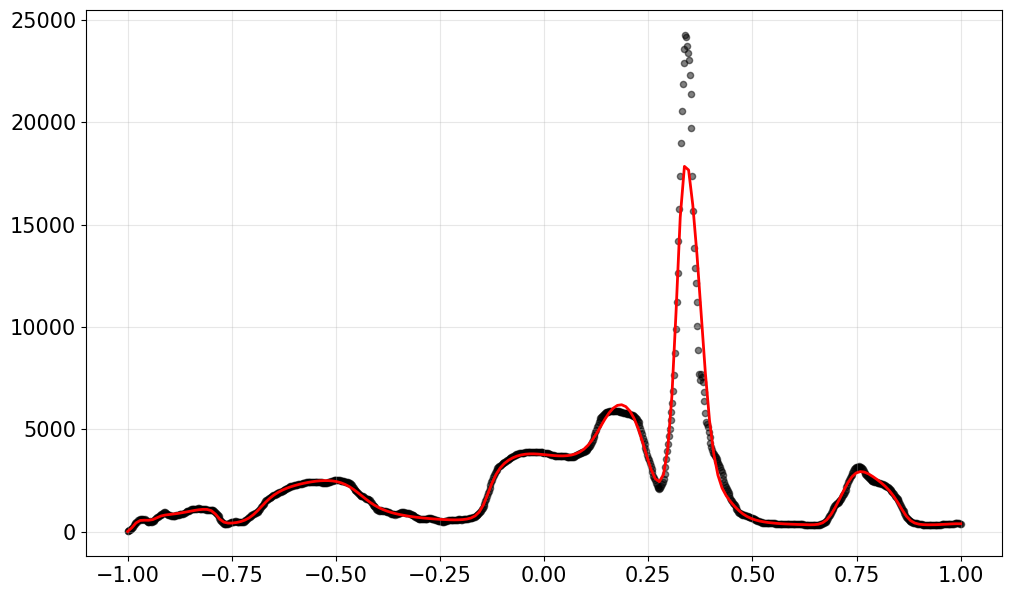

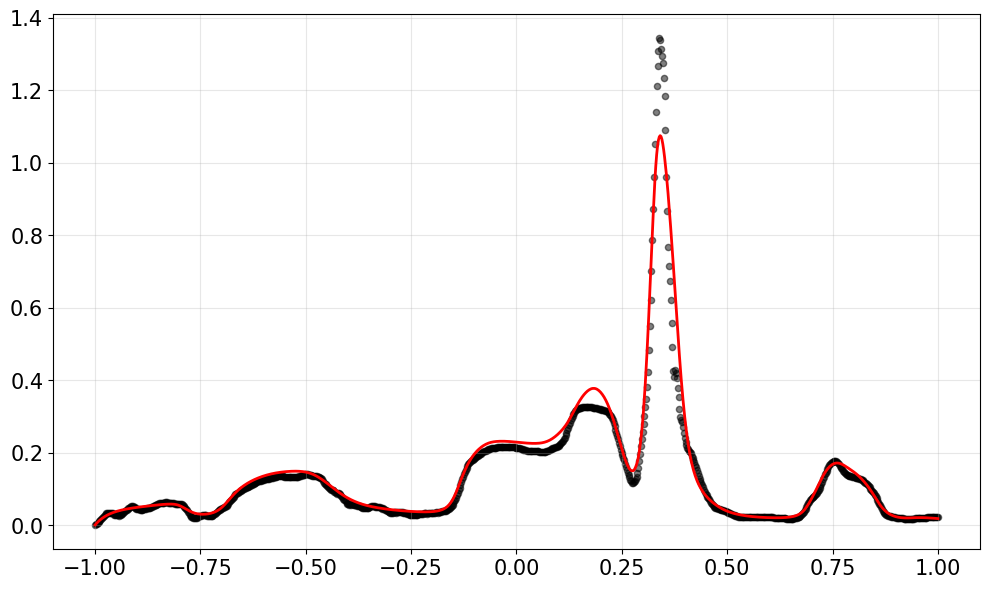

In [18]:
t_test = torch.linspace(-1, 1, 200, device=device).reshape(-1,1)
E_pred, I_pred, R_pred, beta_pred, sigma_pred, gamma_pred, E0_pred = model_new(t_test)
S_pred = N_POP - E_pred - I_pred - R_pred

S_pred_omsk = S_pred.cpu().detach().numpy()
E_pred = E_pred.cpu().detach().numpy()    
I_pred = I_pred.cpu().detach().numpy()
R_pred = R_pred.cpu().detach().numpy()
beta_pred_omsk = beta_pred.cpu().detach().numpy()
sigma_pred_omsk = sigma_pred.cpu().detach().numpy()
gamma_pred_omsk = gamma_pred.cpu().detach().numpy()

plt.figure(figsize=(10, 6))
# plt.plot(t_test, S_pred, label="S_pred", linewidth=2, color='blue')
# plt.plot(t_test, E_pred, label="E_pred", linewidth=2, color='purple')
plt.plot(t_test.cpu().numpy().flatten(), I_pred*POP_TOTAL/N_POP, label="I_pred", linewidth=2, color='red')
# plt.plot(t_test, R_pred, label="R_pred", linewidth=2, color='black')
plt.scatter(days, I_omsk.flatten(), s=20, label="I_true", alpha=0.5, color='black')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.tick_params(labelsize=15)
plt.show()


beta_interp = interp1d(t_test.cpu().numpy().flatten(), beta_pred_omsk.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')
sigma_interp = interp1d(t_test.cpu().numpy().flatten(), sigma_pred_omsk.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')
gamma_interp = interp1d(t_test.cpu().numpy().flatten(), gamma_pred_omsk.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')

E0_found = 5*torch.sigmoid(model_new.E0_raw).item()

I0 = I_data[0].item()
E0 = E0_found
R0 = 0.0
S0 = N_POP - I0 - E0 - R0
t_eval = np.linspace(-1, 1, T)
sol = solve_ivp(sir_ode, (-1, 1), [S0, E0, I0, R0], t_eval=t_eval, rtol=1e-8)

S_ode = sol.y[0]
E_ode = sol.y[1]
I_ode_omsk = sol.y[2]
R_ode = sol.y[3]

plt.figure(figsize=(10, 6))
# plt.plot(t_eval_norm, S_ode, 'r-', label='I (reverse)', linewidth=2)
# plt.plot(t_eval, E_ode, 'g-', label='E (reverse)', linewidth=2)
plt.plot(t_eval, I_ode_omsk, label="I_pred", linewidth=2, color='red')
# plt.plot(t_test, R_pred, label="R_pred", linewidth=2, color='black')
plt.scatter(days, I_data.flatten(), s=20, label="I_true", alpha=0.5, color='black')
plt.grid(True, alpha=0.3)
plt.tick_params(labelsize=15)

plt.tight_layout()
plt.show()

## Алтайский край

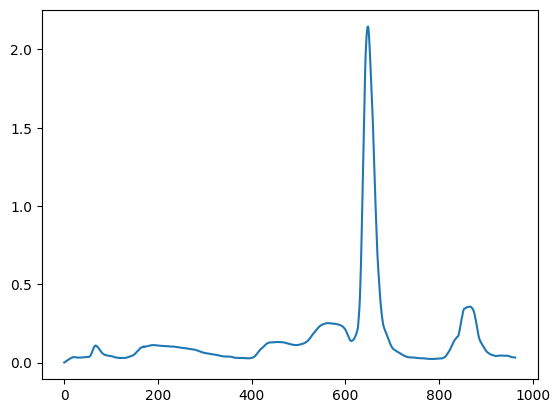

C:\Users\Yascher\AppData\Local\Temp\ipykernel_31980\4057094897.py:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  I0_frac_new = float(I_data[0])


Epoch 0, loss=474.417725, loss_data=0.504516
Epoch 500, loss=9.046916, loss_data=0.126071
Epoch 1000, loss=4.384058, loss_data=0.062024
Epoch 1500, loss=2.558906, loss_data=0.035088
Epoch 2000, loss=1.635530, loss_data=0.020616
Epoch 2500, loss=1.140831, loss_data=0.013099
Epoch 3000, loss=0.872180, loss_data=0.009037
Epoch 3500, loss=0.706088, loss_data=0.006635
Epoch 4000, loss=0.612819, loss_data=0.005286
Epoch 4500, loss=0.561601, loss_data=0.004580
Epoch 5000, loss=0.527005, loss_data=0.004132


In [19]:
N_POP = 100
POP_TOTAL = 2099186
df_altay = pd.read_csv('altay-region-data.csv')
I_frac_new = df_altay['new_diagnoses'][44:1007].to_numpy()
cases_smooth = pd.Series(I_frac_new).rolling(window=7, min_periods=1, center=True).mean().to_numpy()
DISEASE_DURATION = 10  # дней
dates_altay, dates_pred_altay = get_region_dates(df_altay, date_col='date', start_idx=44, end_idx=1007, n_points=200)
I_window_sum = pd.Series(I_frac_new).rolling(
    window=DISEASE_DURATION, 
    min_periods=1
).sum().to_numpy()
I_altay = I_window_sum[:, None]
I_data = (I_window_sum)[:, None] / POP_TOTAL * N_POP
T = len(I_data)
plt.plot(I_data)
plt.show()
model_new = PINN_with_params([1, 128, 128, 128, 128, 128, 3], [1, 128, 128, 128, 3], N_POP, T).to(device)

checkpoint = torch.load('pinn_seir_nsk.pth')
model_new.load_state_dict(checkpoint['model_state_dict'])
loss_w = checkpoint['loss_weights']
loss_weights = (loss_w['w_pde_S'], loss_w['w_pde_E'], loss_w['w_pde_I'], loss_w['w_pde_R'], loss_w['w_ic_E'], loss_w['w_ic_I'], loss_w['w_ic_R'], loss_w['w_data_I'], loss_w['w_mono_S'], loss_w['w_mono_R'])

I0_frac_new = float(I_data[0])
E0_frac_new = I0_frac_new * 3.0
R0_frac_new = 0.0
S0_frac_new = N_POP - I0_frac_new - E0_frac_new - R0_frac_new

I0_new = torch.tensor([[I0_frac_new * N_POP]], dtype=torch.float32, device=device)
# E0_new = torch.tensor([[E0_frac_new * N_POP]], dtype=torch.float32, device=device)
R0_new = torch.tensor([[R0_frac_new * N_POP]], dtype=torch.float32, device=device)
S0_new = torch.tensor([[S0_frac_new * N_POP]], dtype=torch.float32, device=device)


days = np.linspace(-1, 1, len(I_data))[:, None]
t_data_new = torch.tensor(days, dtype=torch.float32, device=device)  # дни те же
I_data_tensor_new = torch.tensor(I_data, dtype=torch.float32, device=device)


optimizer_finetune = torch.optim.Adam(
    model_new.parameters(), 
    lr=loss_w['lr']/15,
    weight_decay=loss_w['weight_decay']
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_finetune,
    mode='min',
    factor=0.5,
    patience=300,
    min_lr=1e-6
)


for epoch in range(5001):
    optimizer_finetune.zero_grad()
    
    loss, loss_data = loss_fn_params(
        model_new,
        t_colloc,
        t_data_new,
        I_data_tensor_new,
        S0_new, I0_new, R0_new,
        weights=loss_weights
    )
    
    loss.backward()
    optimizer_finetune.step()
    scheduler.step(loss)
    
    if epoch % 500 == 0:
        print(f"Epoch {epoch}, loss={loss.item():.6f}, loss_data={loss_data:.6f}")

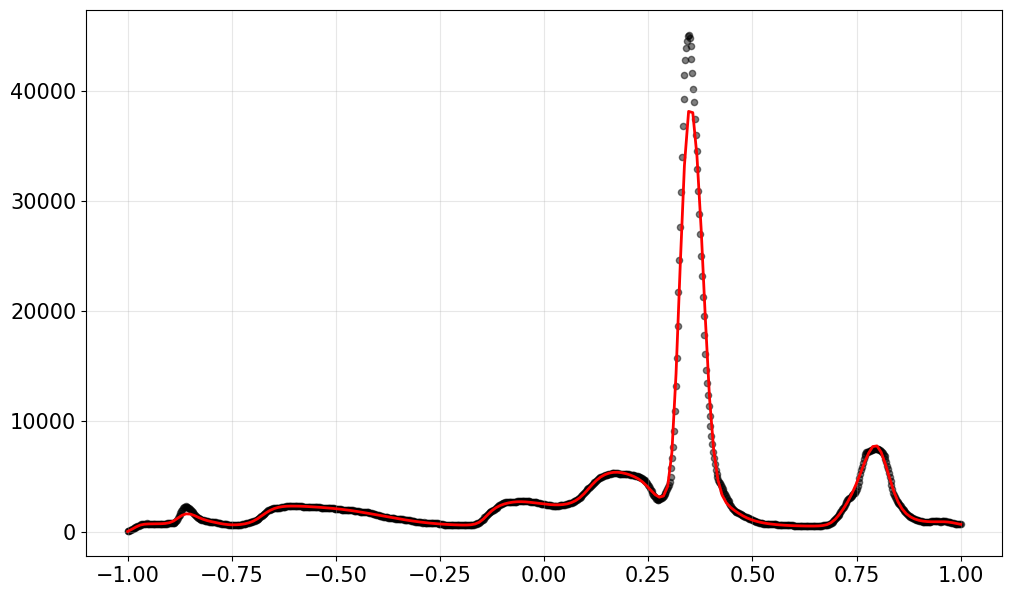

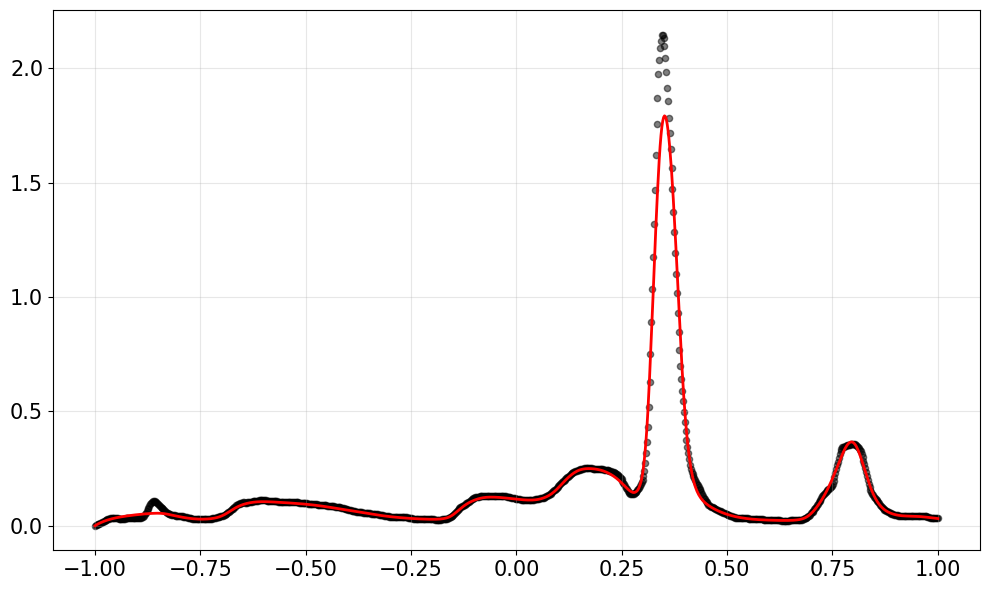

In [21]:
t_test = torch.linspace(-1, 1, 200, device=device).reshape(-1,1)
E_pred, I_pred, R_pred, beta_pred, sigma_pred, gamma_pred, E0_pred = model_new(t_test)
S_pred = N_POP - E_pred - I_pred - R_pred

S_pred_altay = S_pred.cpu().detach().numpy()
E_pred = E_pred.cpu().detach().numpy()    
I_pred = I_pred.cpu().detach().numpy()
R_pred = R_pred.cpu().detach().numpy()
beta_pred_altay = beta_pred.cpu().detach().numpy()
sigma_pred_altay = sigma_pred.cpu().detach().numpy()
gamma_pred_altay = gamma_pred.cpu().detach().numpy()

plt.figure(figsize=(10, 6))
# plt.plot(t_test, S_pred, label="S_pred", linewidth=2, color='blue')
# plt.plot(t_test, E_pred, label="E_pred", linewidth=2, color='purple')
plt.plot(t_test.cpu().numpy().flatten(), I_pred*POP_TOTAL/N_POP, label="I_pred", linewidth=2, color='red')
# plt.plot(t_test, R_pred, label="R_pred", linewidth=2, color='black')
plt.scatter(days, I_altay.flatten(), s=20, label="I_true", alpha=0.5, color='black')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.tick_params(labelsize=15)
plt.show()

beta_interp = interp1d(t_test.cpu().numpy().flatten(), beta_pred_altay.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')
sigma_interp = interp1d(t_test.cpu().numpy().flatten(), sigma_pred_altay.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')
gamma_interp = interp1d(t_test.cpu().numpy().flatten(), gamma_pred_altay.flatten(), kind='linear', bounds_error=False, fill_value='extrapolate')

E0_found = 5*torch.sigmoid(model_new.E0_raw).item()

I0 = I_data[0].item()
E0 = E0_found
R0 = 0.0
S0 = N_POP - I0 - E0 - R0
t_eval = np.linspace(-1, 1, T)
sol = solve_ivp(sir_ode, (-1, 1), [S0, E0, I0, R0], t_eval=t_eval, rtol=1e-8)

S_ode = sol.y[0]
E_ode = sol.y[1]
I_ode_altay = sol.y[2]
R_ode = sol.y[3]

plt.figure(figsize=(10, 6))
# plt.plot(t_eval_norm, S_ode, 'r-', label='I (reverse)', linewidth=2)
# plt.plot(t_eval, E_ode, 'g-', label='E (reverse)', linewidth=2)
plt.plot(t_eval, I_ode_altay, label="I_pred", linewidth=2, color='red')
# plt.plot(t_test, R_pred, label="R_pred", linewidth=2, color='black')
plt.scatter(days, I_data.flatten(), s=20, label="I_true", alpha=0.5, color='black')
plt.grid(True, alpha=0.3)
plt.tick_params(labelsize=15)

plt.tight_layout()
plt.show()

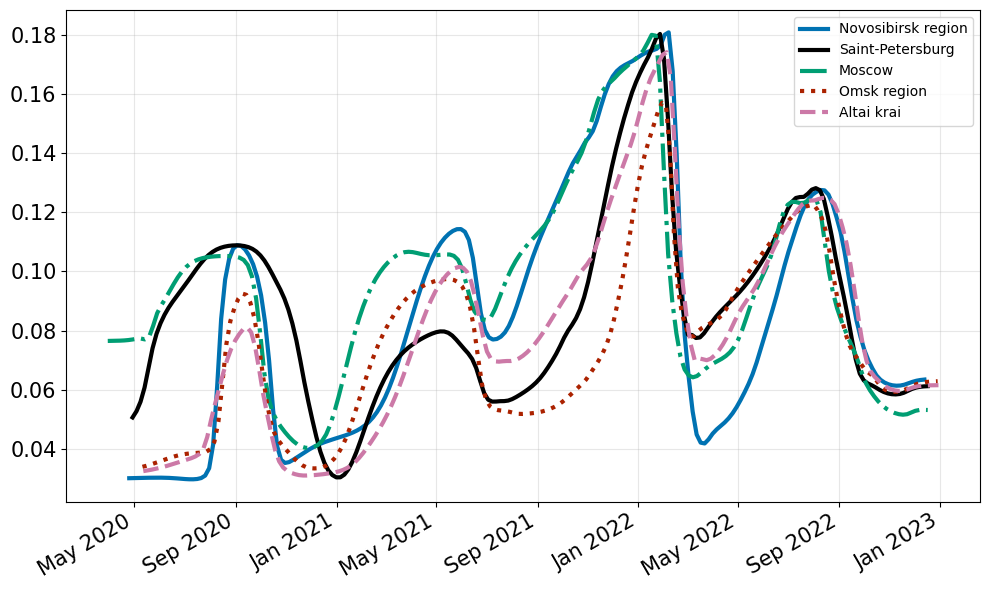

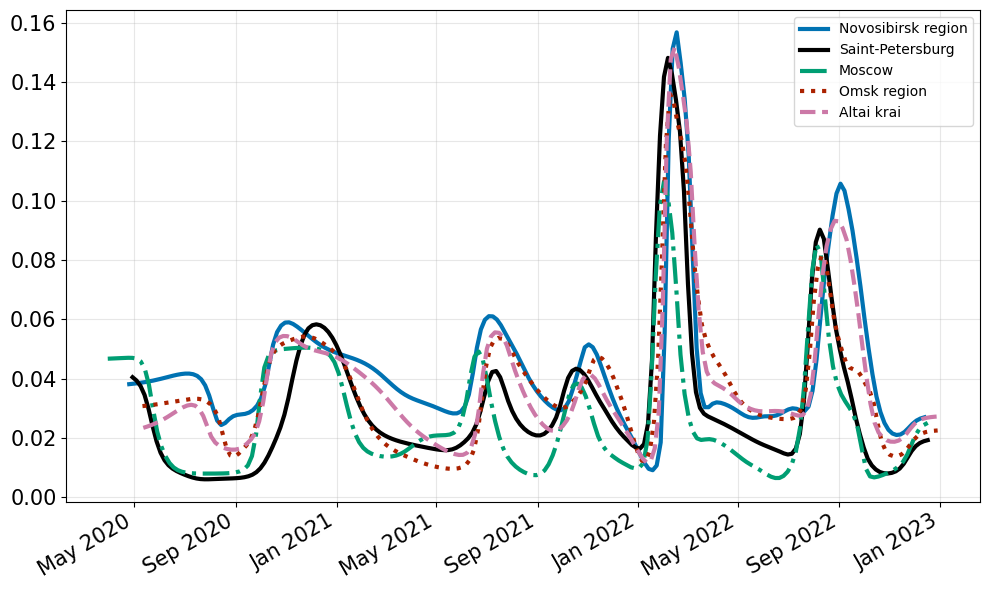

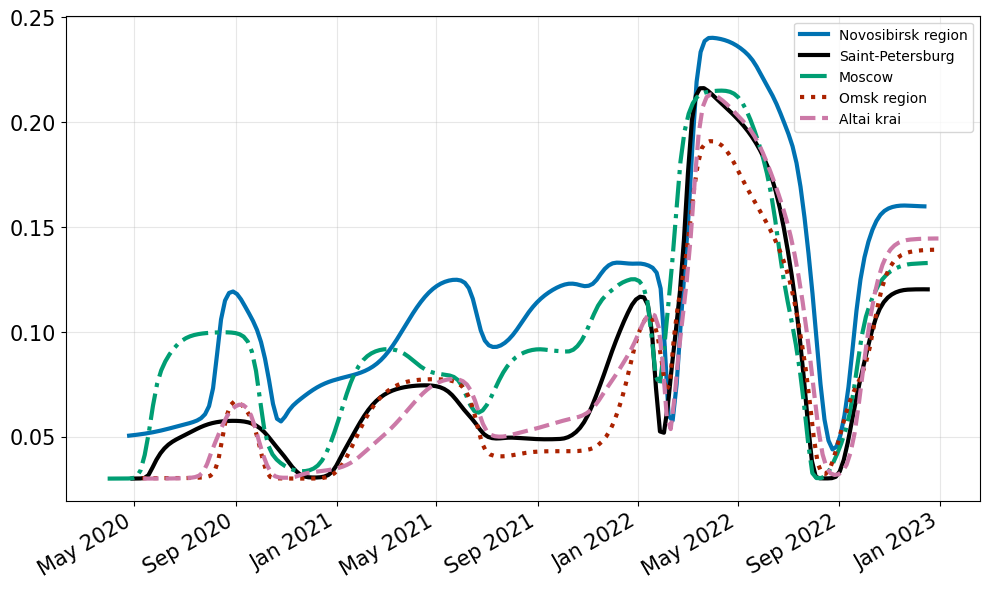

In [22]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(dates_pred_nsk, beta_pred_nsk/963*2, label="Novosibirsk region", color='#0072B2', linewidth=3)
ax.grid(True, alpha=0.3)
ax.plot(dates_pred_spb, beta_pred_spb/963*2, label="Saint-Petersburg", color='black', linewidth=3)
ax.plot(dates_pred_msk, beta_pred_msk/993*2, label="Moscow", color='#009E73', linestyle='-.', linewidth=3)
ax.plot(dates_pred_omsk, beta_pred_omsk/963*2, label="Omsk region", color="#AB2200", linestyle=':', linewidth=3)
ax.plot(dates_pred_altay, beta_pred_altay/963*2, label="Altai krai", color='#CC79A7', linestyle='dashed', linewidth=3)

plt.legend()
ax.tick_params(labelsize=15)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, alpha=0.3)
ax.plot(dates_pred_nsk, sigma_pred_nsk/963*2, label="Novosibirsk region", color='#0072B2', linewidth=3)
ax.plot(dates_pred_spb, sigma_pred_spb/963*2, label="Saint-Petersburg", color='black', linewidth=3)
ax.plot(dates_pred_msk, sigma_pred_msk/993*2, label="Moscow", color='#009E73', linestyle='-.', linewidth=3)
ax.plot(dates_pred_omsk, sigma_pred_omsk/963*2, label="Omsk region", color="#AB2200", linestyle=':', linewidth=3)
ax.plot(dates_pred_altay, sigma_pred_altay/963*2, label="Altai krai", color='#CC79A7', linestyle='dashed', linewidth=3)
ax.tick_params(labelsize=15)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.tight_layout()
plt.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, alpha=0.3)
ax.plot(dates_pred_nsk, gamma_pred_nsk/963*2, label="Novosibirsk region", color='#0072B2', linewidth=3)
ax.plot(dates_pred_spb, gamma_pred_spb/963*2, label="Saint-Petersburg", color='black', linewidth=3)
ax.plot(dates_pred_msk, gamma_pred_msk/993*2, label="Moscow", color='#009E73', linestyle='-.', linewidth=3)
ax.plot(dates_pred_omsk, gamma_pred_omsk/963*2, label="Omsk region", color="#AB2200", linestyle=':', linewidth=3)
ax.plot(dates_pred_altay, gamma_pred_altay/963*2, label="Altai krai", color='#CC79A7', linestyle='dashed', linewidth=3)
ax.tick_params(labelsize=15)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.tight_layout()
plt.legend()
plt.show()

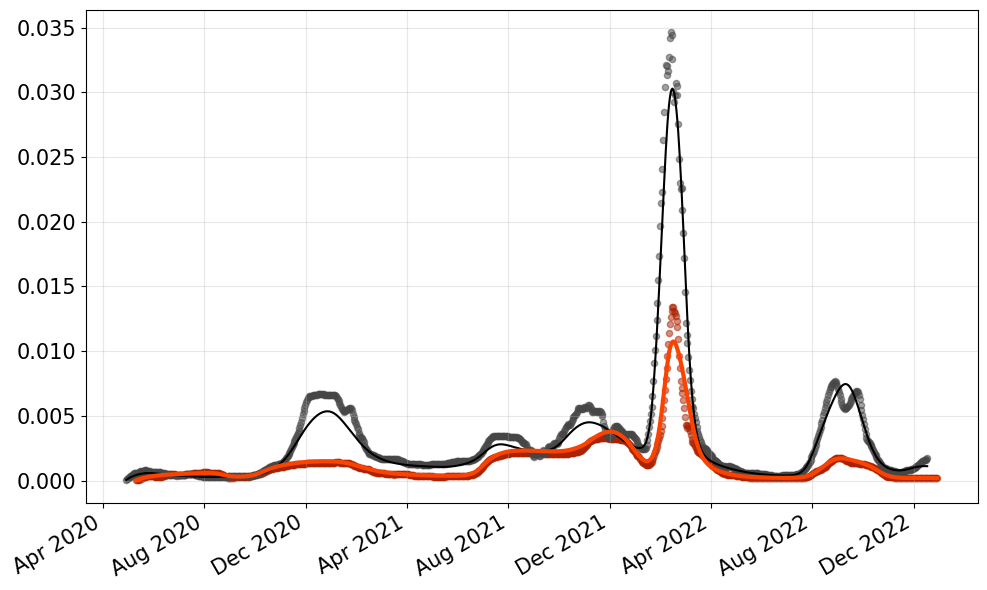

In [23]:
R0_nsk = beta_pred_nsk / gamma_pred_nsk
R0_spb = beta_pred_spb / gamma_pred_spb
R0_mos = beta_pred_msk / gamma_pred_msk
R0_omsk = beta_pred_omsk / gamma_pred_omsk
R0_alt = beta_pred_altay / gamma_pred_altay

fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, alpha=0.3)
days_msk = np.linspace(-1, 1, len(I_ode_msk))[:, None]
# ax.plot(dates_nsk[240:740], I_ode_nsk[240:740]/2000, label="Новосибирская область", color='#0072B2')
ax.plot(dates_spb, I_ode_spb/100, label="Санкт-Петербург", color='black')
# ax.plot(dates_msk, I_ode_msk/50, label="Москва", color="#054544", linewidth=2)
ax.plot(dates_omsk, I_ode_omsk/100, label="Омская область", color="#FA4300", linewidth=3)
# ax.plot(dates_altay, I_ode_altay/100, label="Алтайский край", color="#B60566", linewidth=2)
# ax.scatter(dates_nsk[240:740], I_data[240:740].flatten()/2000, s=20, label="Данные Новосибирской области", alpha=0.5, color='#0072B2')
# ax.scatter(dates_msk, I_msk.flatten()/13274285, s=20, label="Данные Москвы", alpha=0.5, color="#1A8195")
ax.scatter(dates_omsk, I_omsk.flatten()/1805806, s=20, label="Данные для Омской области", alpha=0.5, color="#AB2200")
ax.scatter(dates_spb, I_spb.flatten()/5652922, s=20, label="Данные Санкт-Петербурга", alpha=0.5, color="#474647")
# ax.scatter(dates_altay, I_altay.flatten()/2099186, s=20, label="I_true_altay", alpha=0.5, color="#B4568A")
ax.tick_params(labelsize=15)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

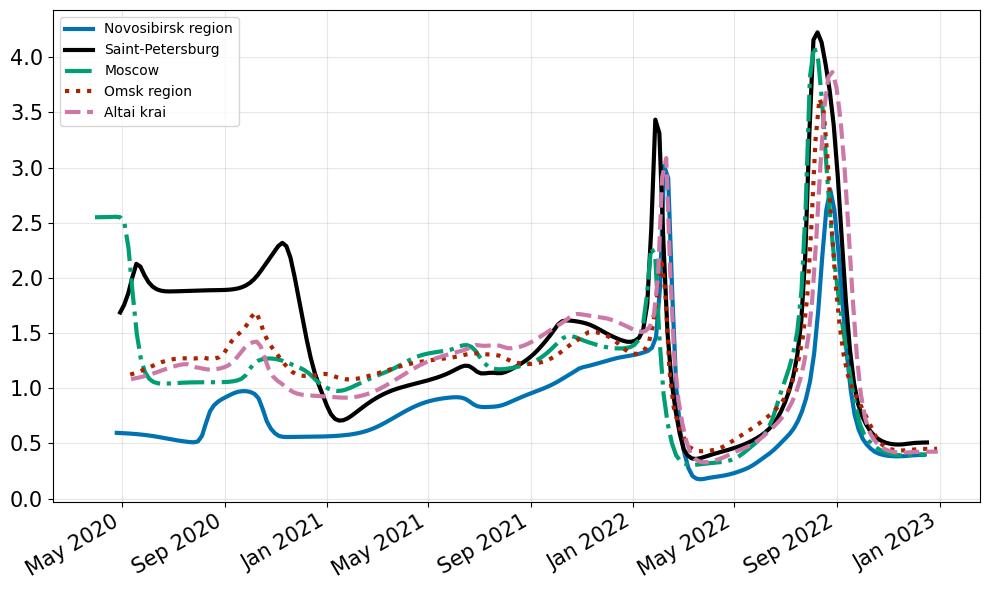

In [24]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, alpha=0.3)
ax.plot(dates_pred_nsk, R0_nsk, label="Novosibirsk region", color='#0072B2', linewidth=3)
ax.plot(dates_pred_spb, R0_spb, label="Saint-Petersburg", color='black', linewidth=3)
ax.plot(dates_pred_msk, R0_mos, label="Moscow", color='#009E73', linestyle='-.', linewidth=3)
ax.plot(dates_pred_omsk, R0_omsk, label="Omsk region", color="#AB2200", linestyle=':', linewidth=3)
ax.plot(dates_pred_altay, R0_alt, label="Altai krai", color='#CC79A7', linestyle='dashed', linewidth=3)
ax.tick_params(labelsize=15)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.legend()
plt.tight_layout()
plt.show()